# JCP Fall 26 — Week 4: PCA, KNN, and Cross-Validation

This notebook goes with the Week 4 slides. Every section uses the same cell types as the review notebook:

1. **Predict**: read the cell and write your guess in the `# Guess:` comment *before* you run it.
2. **Fix**: the cell is broken on purpose. Read the error, find the bug, fix it.
3. **Tinker**: change one value, rerun, and notice what changes.
4. **Your Turn**: replace every `...` with your own code.

Examples use **`wine`** (178 Italian wines, 13 chemical measurements, 3 grape cultivars). Your Turn cells use **`penguins`** (342 penguins, 4 body measurements, 3 species), which you'll download from Kaggle. Same skills, different data, so you write the code yourself instead of copying it.

Keep each cell short. If you're stuck for more than 2 minutes, ask your partner, then ask us.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

In [2]:
# Wine is built into scikit-learn, no download needed
wine = load_wine(as_frame=True).frame
wine["cultivar"] = wine["target"].map({0: "cultivar_1", 1: "cultivar_2", 2: "cultivar_3"})
wine = wine.drop(columns="target")
wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,cultivar_1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,cultivar_1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,cultivar_1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,cultivar_1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,cultivar_1


In [3]:
X_wine = wine.drop(columns="cultivar")
y_wine = wine["cultivar"]
print(X_wine.shape)
y_wine.value_counts()

(178, 13)


cultivar
cultivar_2    71
cultivar_1    59
cultivar_3    48
Name: count, dtype: int64

---
## 0. Get the Penguins Data

Run the cell below. It loads the penguins data from seaborn and renames two columns so they match the Kaggle version. Then keep going as normal.

In [4]:
penguins = sns.load_dataset("penguins").rename(
    columns={"bill_length_mm": "culmen_length_mm", "bill_depth_mm": "culmen_depth_mm"})
penguins.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Check for missing values in penguins

In [5]:
penguins.isna().sum()

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [6]:
penguins.shape

(344, 7)

We can see that there's two penguin entries with missing values. Since the number of missing rows is less than 5% of the total 344 rows, we can just drop them, and it won't have a signficant impact on our data. Even though the 'sex' column has 11 missing, we don't drop those rows since we won't be using 'sex' in our model, since it's not a numeric feature

In [7]:
# List of all NUMERIC FEATURES we'll be using
PEN_FEATURES = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]

# Drop all rows with missing values in the above numberic rows
penguins = penguins.dropna(subset=PEN_FEATURES).reset_index(drop=True)
X_pen = penguins[PEN_FEATURES]
y_pen = penguins["species"]
print(X_pen.shape)
y_pen.value_counts()

(342, 4)


species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

---
## 1. PCA

**Predict:** look at the `std` row. Which column has by far the biggest spread? Why could that be a problem for PCA?

In [8]:
# Guess: which column has the biggest standard deviation?
X_wine.describe().loc[["mean", "std"]].round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91


**Predict:** we'll run PCA on the **raw, unscaled** wine data. What percent of the variance will PC1 capture?

In [9]:
# Guess: PC1 explains ___% of the variance
pca_raw = PCA(n_components=2)
pca_raw.fit(X_wine)
pca_raw.explained_variance_ratio_.round(3)

array([0.998, 0.002])

Each PC is one weight per original column. Which column is PC1 made of?

In [10]:
pd.Series(pca_raw.components_[0], index=X_wine.columns).round(3)

alcohol                         0.002
malic_acid                     -0.001
ash                             0.000
alcalinity_of_ash              -0.005
magnesium                       0.018
total_phenols                   0.001
flavanoids                      0.002
nonflavanoid_phenols           -0.000
proanthocyanins                 0.001
color_intensity                 0.002
hue                             0.000
od280/od315_of_diluted_wines    0.001
proline                         1.000
dtype: float64

PC1 is basically just proline, because its std is 315 while the next biggest (magnesium) is only 14. That’s not ‘most important’, it’s just ‘biggest units’

**Example:** scale first, then PCA. One step at a time.

In [11]:
# StandardScaler() function rescales each column to have mean of 0 and standard deviation of 1
wine_scaler = StandardScaler()

# fit = compute each column's mean and std
# transform = for every value: (value - column mean) / column std
# fit_transform does both in one step and returns a NumPy array, not a DataFrame
X_wine_scaled = wine_scaler.fit_transform(X_wine)

# Turn it back into a DataFrame so we can see column names, then check the result:
# every column should now have mean 0 and std 1
# (a "-0.0" is just a tiny rounding error, still 0)
pd.DataFrame(X_wine_scaled, columns=X_wine.columns).describe().loc[["mean", "std"]].round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [12]:
# ask PCA for 2 principal components
pca_wine = PCA(n_components=2)

# fit = find the 2 directions where the scaled data spreads out the most
# transform = re-describe every wine using those 2 directions instead of the 13 original columns
# Result: each wine's PC1 and PC2 "scores"
# Call fit_transform on all the x features that are used to predict the final output
wine_pcs = pca_wine.fit_transform(X_wine_scaled)

# Same 178 wines (rows), but 13 columns squeezed down to 2
# NOT JUST 2 ORIGINAL COLUMNS
# Each new column is a blend of the 13 original columns
print("before:", X_wine_scaled.shape)
print("after: ", wine_pcs.shape)

before: (178, 13)
after:  (178, 2)


For each PC, see what fraction of the total spread in data was actually captured

In [13]:
# First number = PC1, second = PC2
# (PC1 is always the largest)
# Add them up to get how much information we kept by going from 13 columns to 2

pca_wine.explained_variance_ratio_.round(3)

array([0.362, 0.192])

We kept 0.362 + 0.192 of the variance in data, which is around 55%

In [14]:
# PC1's recipe now: lots of columns contribute
pd.Series(pca_wine.components_[0], index=X_wine.columns).sort_values().round(2)

nonflavanoid_phenols           -0.30
malic_acid                     -0.25
alcalinity_of_ash              -0.24
color_intensity                -0.09
ash                            -0.00
magnesium                       0.14
alcohol                         0.14
proline                         0.29
hue                             0.30
proanthocyanins                 0.31
od280/od315_of_diluted_wines    0.38
total_phenols                   0.39
flavanoids                      0.42
dtype: float64

The biggest weights here are flavanoids (0.42), total_phenols (0.39) and od280 (0.38), and nonflavanoid_phenols is most negative (-0.30).

**Predict:** PCA never saw the `cultivar` labels. When we plot PC1 vs PC2 and color by cultivar, will the three groups still separate?

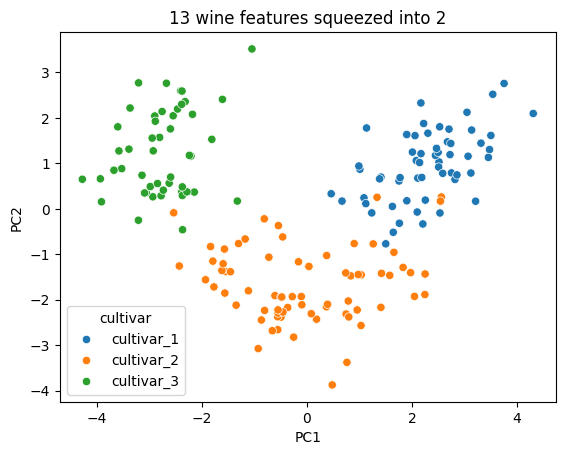

In [15]:
# Guess: separated or mixed together?

# wine_pcs is a NumPy array, so wrap it in a DataFrame with named columns for plotting
wine_pc_df = pd.DataFrame(wine_pcs, columns=["PC1", "PC2"])

# Attach the labels AFTER PCA, only for coloring the plot
# PCA itself never saw these (it's unsupervised)
wine_pc_df["cultivar"] = y_wine

# Each dot is one wine, placed by its PC1 and PC2 scores and colored by its true cultivar
sns.scatterplot(wine_pc_df, x="PC1", y="PC2", hue="cultivar")
plt.title("13 wine features squeezed into 2")
plt.show()

**Example:** how many components do we actually need? Fit PCA with *all* components and add up the variance as we go.

In [16]:
# No n_components = keep all 13 PCs, so we can see how much each one adds
pca_all = PCA()

# Only fit, no transform: we just want the variance numbers, not new columns
pca_all.fit(X_wine_scaled)

# explained_variance_ratio_ = how much each PC captures on its own
# .cumsum() = running total: PC1, then PC1+PC2, then PC1+PC2+PC3, ...
# Read it as "if I keep the first n PCs, I keep this fraction of the information"
cumulative = pca_all.explained_variance_ratio_.cumsum()
cumulative.round(2)

array([0.36, 0.55, 0.67, 0.74, 0.8 , 0.85, 0.89, 0.92, 0.94, 0.96, 0.98,
       0.99, 1.  ])

The first two values match the 2-component PCA from before, and the last is always 1.0, since keeping all 13 PCs keeps everything.

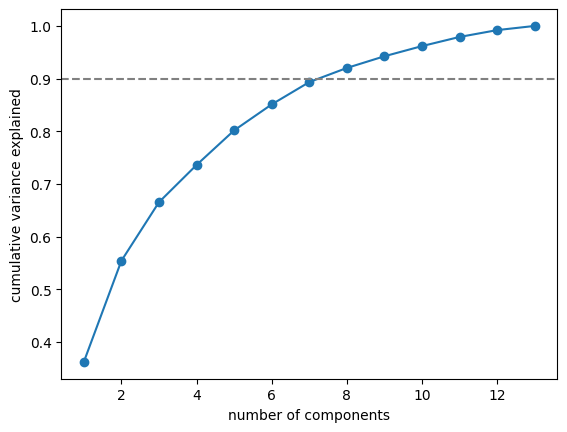

In [17]:
plt.plot(range(1, 14), cumulative, marker="o")
plt.axhline(0.90, color="gray", linestyle="--")
plt.xlabel("number of components")
plt.ylabel("cumulative variance explained")
plt.show()

find the first dot above the dashed line. Here that’s 8 components, so 8 of the 13 columns keep 90% of the information. The curve also flattens toward the right, meaning each extra PC adds less than the one before.

**Tinker:** pass a fraction instead of a number, and sklearn picks how many components to keep. Change `0.90` to `0.80`, then `0.99`. How many components does it keep each time?

In [18]:
pca_90 = PCA(n_components=0.90)
pca_90.fit(X_wine_scaled)
pca_90.n_components_

np.int64(8)

**Fix:** this should scale the wine features and run PCA. Read the error message carefully.

In [19]:
fix_scaler = StandardScaler()
# Bug: `wine` still has the text "cultivar" column, which can't be scaled. Use X_wine (features only)
X_fix = fix_scaler.fit_transform(X_wine)
fix_pcs = PCA(n_components=2).fit_transform(X_fix)
fix_pcs.shape

(178, 2)

**Your Turn:** PCA on `penguins`.

1. Scale `X_pen`.
2. Fit PCA with 2 components and print the explained variance ratio.
3. Plot PC1 vs PC2, colored by `species`.

In [20]:
pen_scaler = StandardScaler()
X_pen_scaled = pen_scaler.fit_transform(X_pen)

pca_pen = PCA(n_components=2)
pen_pcs = pca_pen.fit_transform(X_pen_scaled)
pca_pen.explained_variance_ratio_.round(3)

array([0.688, 0.193])

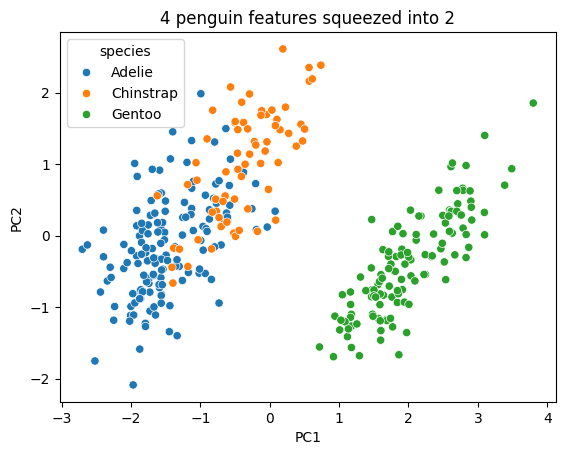

In [21]:
pen_pc_df = pd.DataFrame(pen_pcs, columns=["PC1", "PC2"])
pen_pc_df["species"] = y_pen

sns.scatterplot(pen_pc_df, x="PC1", y="PC2", hue="species")
plt.title("4 penguin features squeezed into 2")
plt.show()

4. Fit PCA with all components on `X_pen_scaled` and print the cumulative explained variance. How many components do you need to reach 90%?

**Answer:** 3 components. The running total is 0.69, 0.88, 0.97, 1.0, so 2 PCs fall just short of 90% and 3 PCs reach 97%.

In [22]:
pca_pen_all = PCA()
pca_pen_all.fit(X_pen_scaled)
pen_cumulative = pca_pen_all.explained_variance_ratio_.cumsum()
pen_cumulative.round(2)

array([0.69, 0.88, 0.97, 1.  ])

*PC1 explains about 36% for wine but about 69% for penguins. Why do you think penguin features overlap so much more?*

The four penguin measurements all describe one thing: how big the penguin is. A bigger penguin tends to have longer flippers, a heavier body and a longer culmen, so the columns are strongly correlated and one direction (overall size) captures most of the spread. Wine has 13 measurements of different chemistry (acidity, alcohol, color, phenols...) that vary more independently, so the variance is spread across many more directions.

---
## 2. K-Nearest Neighbors

KNN predicts a new wine's cultivar by finding the `k` most similar wines it has already seen and letting them vote.

**Example:** split first, *then* scale. The scaler learns its mean and std from the training set only, then reuses them on the test set.

In [23]:
# Split into train (75%) and test (25%)
# Train = the wines KNN gets to "remember"
# Test  = pretend-new wines we hide until the end to check how well it does
# stratify=y_wine keeps the same mix of cultivars in both sets
# random_state=42 makes the split the same every time we rerun

X_train_wine, X_test_wine, y_train_wine, y_test_wine = train_test_split(
    X_wine,
    y_wine,
    test_size=0.25,
    random_state=42,
    stratify=y_wine
    )

print("train:", X_train_wine.shape, " test:", X_test_wine.shape)

train: (133, 13)  test: (45, 13)


133 wines to learn from, 45 wines to test on. Every wine still has all 13 features.

In [24]:
# KNN measures distance, so features need the same units (same reason as PCA)
knn_scaler = StandardScaler()

# fit_transform on TRAIN: learn each column's mean and std, then scale
X_train_wine_s = knn_scaler.fit_transform(X_train_wine)

# transform on TEST: reuse train's mean and std, no new fitting
# If we fit on test too, we'd be peeking at data that's supposed to be "new"
X_test_wine_s = knn_scaler.transform(X_test_wine)

In [25]:
# k = 5: each prediction is a vote among the 5 closest training wines
knn = KNeighborsClassifier(n_neighbors=5)

# fit = just store the training wines and their labels (no real "learning" happens)
knn.fit(X_train_wine_s, y_train_wine)

# score = predict every test wine, then return the fraction it got right (accuracy)
knn.score(X_test_wine_s, y_test_wine)

0.9333333333333333

About 0.93, so KNN got 42 of the 45 test wines right.

**Example:** look inside the vote. Take one test wine, find its 5 nearest training wines, and see what they are.

In [26]:
# Grab the first test wine
# Double brackets [[0]] keep it as a table with 1 row, which is what sklearn expects
one_wine = X_test_wine_s[[0]]

# kneighbors    = find the 5 closest training wines
# distances     = how far away each one is (smaller = more similar)
# neighbor_rows = which rows of the training set they are
distances, neighbor_rows = knn.kneighbors(one_wine)

# Look up the true cultivar of each neighbor: this is the "vote"
print("neighbor labels:", y_train_wine.iloc[neighbor_rows[0]].tolist())
print("distances:      ", distances[0].round(2))
print("prediction:     ", knn.predict(one_wine)[0])   # the majority of the vote
print("actual:         ", y_test_wine.iloc[0])        # the real answer

neighbor labels: ['cultivar_1', 'cultivar_1', 'cultivar_1', 'cultivar_1', 'cultivar_1']
distances:       [1.39 1.9  1.92 1.96 1.96]
prediction:      cultivar_1
actual:          cultivar_1


All 5 neighbors are `cultivar_1`, so the vote is 5–0 and the prediction is `cultivar_1`, which is correct. That's the whole algorithm: find the closest wines, take a vote.

**Tinker:** change `[[0]]` to `[[3]]`, `[[10]]`, or any row up to 44. Can you find a wine where the neighbors don't all agree?

**Predict:** same model, but on the **unscaled** data. Higher accuracy, lower, or about the same?

In [27]:
# Guess:
# Exactly the same model, but trained and scored on the UNSCALED columns
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train_wine, y_train_wine)
knn_raw.score(X_test_wine, y_test_wine)

0.7777777777777778

Accuracy drops from about 0.93 to about 0.78. Without scaling, proline (in the hundreds) decides almost the whole distance, so KNN is basically comparing wines on one column. Same problem we saw with PCA.

**Predict:** with `k=1`, each training wine's nearest neighbor is *itself*. What will training accuracy be? Compare it to test accuracy.

In [28]:
# Guess: training accuracy with k=1 = ___

# k=1: copy the label of the single closest wine
knn_1 = KNeighborsClassifier(n_neighbors=1)
knn_1.fit(X_train_wine_s, y_train_wine)

# Score on the wines it memorized, then on wines it has never seen
print("train:", round(knn_1.score(X_train_wine_s, y_train_wine), 3))
print("test: ", round(knn_1.score(X_test_wine_s, y_test_wine), 3))

train: 1.0
test:  0.956


Train accuracy is a perfect 1.0, because every training wine's closest match is itself. That tells us nothing: of course it gets the answers it memorized. Test accuracy (about 0.96) is the honest number. This is why we always judge a model on data it hasn't seen.

**Fix:** this cell has **two** bugs. Run it, fix the first error, run it again, fix the second. Hint: hover over a function name to see what arguments it takes.

In [29]:
# Bug 1: the argument is n_neighbors, not k
knn_fix = KNeighborsClassifier(n_neighbors=5)
knn_fix.fit(X_train_wine_s, y_train_wine)
# Bug 2: score needs the true labels too, so it can compare them to the predictions
knn_fix.score(X_test_wine_s, y_test_wine)

0.9333333333333333

**Your Turn:** classify penguin `species` using only `culmen_length_mm` and `body_mass_g`.

1. Select the 2 columns, then split 75/25 with `random_state=42` and `stratify=y_pen`.
2. Scale: `fit_transform` on train, `transform` on test.
3. Fit `KNeighborsClassifier(n_neighbors=7)` and print the test accuracy.

In [30]:
X_two = penguins[["culmen_length_mm", "body_mass_g"]]
X_train_two, X_test_two, y_train_two, y_test_two = train_test_split(
    X_two, y_pen, test_size=0.25, random_state=42, stratify=y_pen)

In [31]:
two_scaler = StandardScaler()
X_train_two_s = two_scaler.fit_transform(X_train_two)
X_test_two_s = two_scaler.transform(X_test_two)

In [32]:
pen_knn = KNeighborsClassifier(n_neighbors=7)
pen_knn.fit(X_train_two_s, y_train_two)
pen_knn.score(X_test_two_s, y_test_two)

0.9534883720930233

4. Now fit the same model on the **unscaled** `X_train_two` and score it on `X_test_two`. How much did accuracy drop? Which of the two columns was secretly deciding the distance?

**Answer:** Accuracy drops from about 0.95 (scaled) to about 0.79 (unscaled). `body_mass_g` was secretly deciding the distance: it's in the thousands (std around 800 g), while `culmen_length_mm` only varies by a few mm, so differences in culmen length barely change the distance.

In [33]:
pen_knn_raw = KNeighborsClassifier(n_neighbors=7)
pen_knn_raw.fit(X_train_two, y_train_two)
pen_knn_raw.score(X_test_two, y_test_two)

0.7906976744186046

---
## 3. Cross-Validation

**Predict:** we'll split the wine data 5 different ways. The only thing that changes is `random_state`. Will the test accuracy be the same every time?

In [34]:
# Guess: same every time, or different?
for seed in [0, 1, 2, 3, 4]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_wine, y_wine, test_size=0.25, random_state=seed, stratify=y_wine)
    seed_scaler = StandardScaler().fit(X_tr)
    seed_knn = KNeighborsClassifier(n_neighbors=5).fit(seed_scaler.transform(X_tr), y_tr)
    print(f"random_state={seed}: accuracy = {seed_knn.score(seed_scaler.transform(X_te), y_te):.3f}")

random_state=0: accuracy = 0.933
random_state=1: accuracy = 0.933


random_state=2: accuracy = 0.911
random_state=3: accuracy = 0.978
random_state=4: accuracy = 0.933


Same model, same data, a 7-point swing just from which rows landed in the test set. That's why one split isn't enough.

**Example:** a pipeline glues the scaler and the model into one object. When `cross_val_score` uses it, the scaler is refit inside every fold, so the validation fold never leaks into training.

In [35]:
knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the 

Notice we cross-validate on the **training** set only. The test set stays locked away until the very end.

In [36]:
cv_scores = cross_val_score(knn_pipe, X_train_wine, y_train_wine, cv=5)
print("each fold:", cv_scores.round(3))
print("mean:     ", cv_scores.mean().round(3))

each fold: [1.    0.889 0.963 0.962 0.962]
mean:      0.955


**Tinker:** change `cv=5` to `cv=3`, then `cv=10`. Does the mean move much? Do the individual fold scores get jumpier as each fold gets smaller?

**Example:** use CV to pick `k`. For each `k`, get the mean CV score, then choose the best one.

In [37]:
for k in [1, 3, 5, 9, 15, 25, 49]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    mean_score = cross_val_score(pipe, X_train_wine, y_train_wine, cv=5).mean()
    print(f"k={k:>2}: mean CV accuracy = {mean_score:.3f}")

k= 1: mean CV accuracy = 0.954
k= 3: mean CV accuracy = 0.962
k= 5: mean CV accuracy = 0.955
k= 9: mean CV accuracy = 0.962
k=15: mean CV accuracy = 0.977
k=25: mean CV accuracy = 0.977
k=49: mean CV accuracy = 0.962


`k=15` and `k=25` tie for best. Pick one, train on the full training set, and touch the test set **once**.

In [38]:
final_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
final_pipe.fit(X_train_wine, y_train_wine)
final_pipe.score(X_test_wine, y_test_wine)

1.0

**Fix:** this should run 5-fold cross-validation.

In [39]:
# Bug: the argument is cv, not folds
cross_val_score(knn_pipe, X_train_wine, y_train_wine, cv=5)

array([1.        , 0.88888889, 0.96296296, 0.96153846, 0.96153846])

**Your Turn:** pick the best `k` for penguins using only `culmen_depth_mm` and `flipper_length_mm`. These two overlap a lot between species, so `k` actually matters here.

1. Select the 2 columns and split 75/25 with `random_state=42` and `stratify=y_pen`.
2. For each `k` in `[1, 5, 15, 49, 101]`, build a pipeline (scaler + KNN) and print the mean 5-fold CV accuracy **on the training set**.

In [40]:
X_hard = penguins[["culmen_depth_mm", "flipper_length_mm"]]
X_train_hard, X_test_hard, y_train_hard, y_test_hard = train_test_split(
    X_hard, y_pen, test_size=0.25, random_state=42, stratify=y_pen)

In [41]:
for k in [1, 5, 15, 49, 101]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    mean_score = cross_val_score(pipe, X_train_hard, y_train_hard, cv=5).mean()
    print(f"k={k:>3}: mean CV accuracy = {mean_score:.3f}")

k=  1: mean CV accuracy = 0.762
k=  5: mean CV accuracy = 0.797
k= 15: mean CV accuracy = 0.812
k= 49: mean CV accuracy = 0.816
k=101: mean CV accuracy = 0.801


3. Fit a pipeline with your best `k` on the full training set and score it on the test set, once.

In [42]:
best_k = 49
best_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
best_pipe.fit(X_train_hard, y_train_hard)
best_pipe.score(X_test_hard, y_test_hard)

0.8023255813953488

*Why does `k=1` do worst? Why does `k=101` start to slip again?*

`k=1` copies the label of the single closest penguin, and these two features overlap a lot between species, so the closest neighbor is often a noisy point from the wrong species. That's overfitting (mean CV accuracy 0.762). Larger `k` averages over more neighbors and smooths out that noise, peaking around `k=49` (0.816). At `k=101` each vote covers about half the ~205 penguins in a training fold, so the neighborhood reaches far past the local area and drifts toward the most common species (Adelie). That's underfitting, and smaller groups like Chinstrap get outvoted. With `k=49` the test accuracy was about 0.80, close to the CV estimate.

---
## Done: Push Your Work

Run these in your terminal (not in this notebook):

```
git add Week4.ipynb
git commit -m "week 4 notebook"
git push origin YOUR-BRANCH-NAME
```